# Exploratory data analysis: a year of bike-shop orders

**Student notebook** · SDEV2501 Lessons 22-23

Name:

The owner of a small Edmonton bike shop (fictional) sends you a year of sales data with this message:

> *"It's been a strange year. Some months we're slammed, some months it's dead, and I can't tell what's actually going on. Can you take a look?"*

That isn't a question a chart can answer yet. Exploratory data analysis (EDA) turns it into smaller questions that a chart or a number can answer. In this notebook you'll work through six of them, the same six from the "Exercise: What's the appropriate viz?" slide:

| Question | Section |
|---|---|
| What does the distribution of order quantities look like? | 2 |
| Which product categories are most popular? | 2 |
| Are there unusually large orders? | 2 |
| Are order quantities related to unit price? | 3 |
| Are order values different across membership types? | 3 |
| How do monthly orders change over time? | 4 |

Sections 1 to 6 are the code-along. Section 7 is the EDA challenge, which you do on your own with a second file from the same shop.

The data is in `bike_shop_orders.csv` (November 2025 to October 2026) and `workshop_jobs.csv` (March to October 2026). Both are in this folder.

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Get to know your data

Before any chart, find out what you've actually been given. The "Start by getting to know your data" slide has the checklist: size, what a row is, what each column is, types, missing values, duplicates, unexpected values and reasonable ranges.

### 1.1 Load and look

Load `bike_shop_orders.csv` into a DataFrame called `orders`, with `order_date` read as a date. Show its shape and the first few rows.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(..., parse_dates=[...])` | Reads the file and turns the listed columns into datetimes as it loads. |
| `.shape` | An attribute holding (rows, columns). |
| `.head()` | Shows the first five rows. |

In [32]:
orders = pd.read_csv("bike_shop_orders.csv", parse_dates=["order_date"])
print(orders.shape)
orders.head()

(1194, 10)


,order_id,order_date,customer_id,city,membership_type,channel,product_category,product,quantity,unit_price
0,SC-50001,2025-11-01,C1282,Edmonton,Non-member,Online,Clothing,Jersey,1,85
1,SC-50002,2025-11-01,C1503,Spruce Grove,Basic,In-store,Clothing,Winter balaclava,1,29
2,SC-50003,2025-11-02,C1534,Leduc,Non-member,Online,Accessories,Light set,1,65
3,SC-50004,2025-11-02,C1008,Edmonton,Non-member,In-store,Accessories,Lock,2,59
4,SC-50005,2025-11-02,C1298,Edmonton,Basic,In-store,Clothing,Jersey,2,85


Explain what one row of `orders` represents, and sort the columns into numeric, categorical and date columns.

*Your answer:* One row is one order: one customer buying some quantity of one product on one day. Numeric: `quantity`, `unit_price`. Categorical: `city`, `membership_type`, `channel`, `product_category`, `product`. Date: `order_date`. `order_id` and `customer_id` are identifiers, so they're text even though they contain numbers.

### 1.2 Types and missing values

Check the data type of every column and count the missing values in each.

| You'll need | What it's for |
|---|---|
| `.dtypes` | An attribute listing each column's type. |
| `.isna().sum()` | `.isna()` marks every missing cell as True; `.sum()` counts the Trues per column. |

In [33]:
print(orders.dtypes)
orders.isna().sum()

order_id                       str
order_date          datetime64[us]
customer_id                    str
city                           str
membership_type                str
channel                        str
product_category               str
product                        str
quantity                     int64
unit_price                   int64
dtype: object


order_id             0
order_date           0
customer_id          0
city                14
membership_type      0
channel              0
product_category     0
product              0
quantity             0
unit_price           0
dtype: int64

### 1.3 Duplicates and unexpected categories

Count the rows that are exact duplicates of another row. Then list every value in `city` with how often it appears, including missing values.

| You'll need | What it's for |
|---|---|
| `.duplicated().sum()` | `.duplicated()` marks each row that repeats an earlier row; `.sum()` counts them. |
| `orders["city"].value_counts(dropna=...)` | Counts each distinct value. Passing `dropna=False` keeps the missing values in the count. |

In [34]:
print(orders.duplicated().sum())
orders["city"].value_counts(dropna=False)

3


city
Edmonton          733
St. Albert        136
Sherwood Park     109
Spruce Grove       92
Leduc              91
NaN                14
St Albert           9
edmonton            6
Sherwood Park       4
Name: count, dtype: int64

### 1.4 Reasonable ranges

Show summary statistics for the numeric columns.

| You'll need | What it's for |
|---|---|
| `.describe()` | Count, mean, standard deviation, minimum, quartiles and maximum for each numeric column. |

In [35]:
orders.describe()

,order_date,quantity,unit_price
count,1194,1194.000000,1194.000000
mean,2026-05-14 09:18:23.517588,2.093802,533.700168
min,2025-11-01 00:00:00,-1.000000,0.000000
25%,2026-03-16 06:00:00,1.000000,35.000000
50%,2026-05-25 00:00:00,1.000000,65.000000
75%,2026-07-26 00:00:00,2.000000,329.000000
max,2026-10-31 00:00:00,500.000000,4999.000000
std,NaN,14.686312,1064.657559


Explain the data quality concerns you found in 1.2 to 1.4. For each one, say which column it's in and how many rows it affects.

*Your answer:*
- 3 exact duplicate rows.
- `city` has 14 missing values and the same city spelled different ways: `St Albert` (9), `edmonton` (6) and `Sherwood Park ` with a space at the end (4).
- `quantity` has a minimum of -1 and a maximum of 500. Negative quantity doesn't make sense for a sale, and 500 is far above everything else (75% of orders are 2 or fewer).
- `unit_price` has a minimum of 0, so some items were free.

### 1.5 A light clean

EDA isn't the time for a full clean, but three fixes are safe because there's no doubt about the right answer. Remove the duplicate rows. Tidy `city` so each city has one spelling: strip the extra spaces, put it in title case, then replace `"St Albert"` with `"St. Albert"`. Finally, add an `order_value` column equal to `quantity` times `unit_price`. Leave the missing cities and the strange quantities alone for now; section 2 looks at them properly.

| You'll need | What it's for |
|---|---|
| `.drop_duplicates()` | Returns the DataFrame without repeated rows. |
| `.str.strip()`, `.str.title()` | String methods through the `.str` accessor: remove spaces at both ends, and capitalize each word. |
| `.replace(..., ...)` | Swaps one value for another. |
| `orders["new_column"] = ...` | Creating a column from arithmetic on other columns. |

In [36]:
orders = orders.drop_duplicates()
orders["city"] = orders["city"].str.strip().str.title().replace("St Albert", "St. Albert")
orders["order_value"] = orders["quantity"] * orders["unit_price"]
print(orders.shape)
orders["city"].value_counts(dropna=False)

(1191, 11)


city
Edmonton         737
St. Albert       144
Sherwood Park    113
Spruce Grove      92
Leduc             91
NaN               14
Name: count, dtype: int64

## 2. Univariate analysis: one column at a time

Univariate analysis looks at one variable on its own: how it's spread out, what's typical, and what's unusual.

### 2.1 How many items are in an order?

Draw a histogram of `quantity` with a title and axis labels.

| You'll need | What it's for |
|---|---|
| `plt.hist(...)` | Draws a histogram of one numeric column. |
| `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Chart title and axis labels. |
| `plt.show()` | Displays the chart. |

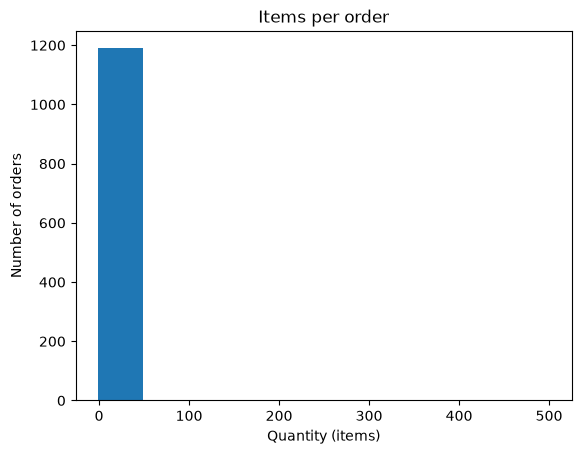

In [37]:
plt.hist(orders["quantity"])
plt.title("Items per order")
plt.xlabel("Quantity (items)")
plt.ylabel("Number of orders")
plt.show()

### 2.2 Are there unusually large orders?

Draw a box plot of `order_value`.

| You'll need | What it's for |
|---|---|
| `plt.boxplot(...)` | Draws a box plot: the box is the middle half of the values, and dots are values beyond the whiskers. |

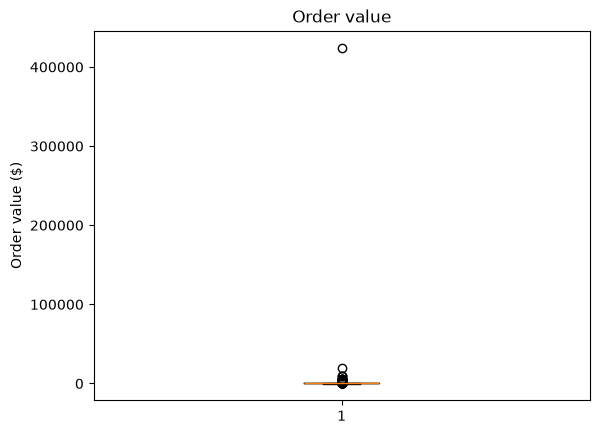

In [38]:
plt.boxplot(orders["order_value"])
plt.title("Order value")
plt.ylabel("Order value ($)")
plt.show()

Both charts are squashed into a thin strip because of a few very large values. Find out what they are: show the orders with a `quantity` of 20 or more, and the five orders with the highest `order_value`.

| You'll need | What it's for |
|---|---|
| `orders[orders["quantity"] >= ...]` | A boolean mask: keeps only the rows where the condition is True. |
| `.sort_values(..., ascending=False).head()` | Sorts by a column from largest to smallest, then shows the top five. |

In [39]:
orders[orders["quantity"] >= 20]

,order_id,order_date,customer_id,city,membership_type,channel,product_category,product,quantity,unit_price,order_value
70,SC-50071,2025-12-04,C1648,Edmonton,Premium,In-store,Clothing,Cycling gloves,30,35,1050
404,SC-50405,2026-04-14,C1641,Edmonton,Basic,In-store,Accessories,Water bottle,40,14,560
490,SC-50491,2026-05-02,C1642,Edmonton,Premium,In-store,Parts,Inner tube,30,12,360
555,SC-50556,2026-05-16,C1137,St. Albert,Basic,In-store,Bikes,Commuter bike,500,849,424500
580,SC-50581,2026-05-21,C1643,St. Albert,Non-member,In-store,Accessories,Helmet,24,89,2136
681,SC-50680,2026-06-09,C1644,Edmonton,Non-member,In-store,Accessories,Water bottle,60,14,840
732,SC-50731,2026-06-18,C1645,Sherwood Park,Basic,In-store,Clothing,Jersey,22,85,1870
826,SC-50825,2026-07-07,C1646,Spruce Grove,Basic,In-store,Parts,Inner tube,25,12,300
993,SC-50991,2026-08-25,C1647,Leduc,Non-member,In-store,Accessories,Light set,20,65,1300


In [40]:
orders.sort_values("order_value", ascending=False).head()

,order_id,order_date,customer_id,city,membership_type,channel,product_category,product,quantity,unit_price,order_value
555,SC-50556,2026-05-16,C1137,St. Albert,Basic,In-store,Bikes,Commuter bike,500,849,424500
332,SC-50333,2026-03-30,C1649,Edmonton,Non-member,In-store,E-bikes,Cargo e-bike,4,4999,19996
773,SC-50772,2026-06-27,C1270,Edmonton,Premium,In-store,E-bikes,Cargo e-bike,2,4999,9998
1086,SC-51084,2026-09-24,C1605,Sherwood Park,Premium,In-store,E-bikes,Cargo e-bike,2,4999,9998
726,SC-50725,2026-06-18,C1012,Spruce Grove,Premium,In-store,E-bikes,Cargo e-bike,2,4999,9998


Explain which of these large orders look like real orders and which look like data errors, and why. Then explain what the -1 quantity probably is.

*Your answer:* The 500 commuter bikes ($424,500) on 16 May is almost certainly an error: it's 100 times bigger than any other bike order, from a regular Basic member, and a small shop wouldn't have 500 bikes. Probably someone typed 500 instead of 5 or 1. The other big orders look real: 20 to 60 cheap items like water bottles, inner tubes, helmets, jerseys and gloves are what a club, school or team would buy, and 4 cargo e-bikes ($19,996) could be a delivery business. The -1 is a returned pannier bag that was recorded as a sale with a negative quantity.

### 2.3 Set aside the error and the return

Make a new DataFrame called `sales` that keeps only the orders with a quantity above 0 and below 500. Use `sales` from here on, and redraw the histogram of `quantity` with one bar per whole number from 1 to 60.

| You'll need | What it's for |
|---|---|
| `(...) & (...)` | Combines two boolean masks; both must be True. Each condition needs its own brackets. |
| `plt.hist(..., bins=range(..., ...))` | Passing a range as `bins` sets the bin edges, so each whole number gets its own bar. |

(1189, 11)


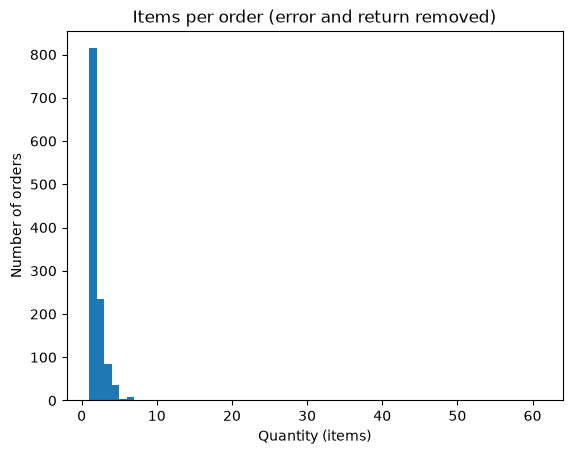

In [41]:
sales = orders[(orders["quantity"] > 0) & (orders["quantity"] < 500)]
print(sales.shape)
plt.hist(sales["quantity"], bins=range(1, 62))
plt.title("Items per order (error and return removed)")
plt.xlabel("Quantity (items)")
plt.ylabel("Number of orders")
plt.show()

### 2.4 Which product categories are most popular?

Count the orders in each `product_category` and draw them as a bar chart.

| You'll need | What it's for |
|---|---|
| `.value_counts()` | Counts each category, largest first. |
| `plt.bar(..., ...)` | Draws one bar per category: the labels first, then the heights. |

product_category
Accessories    365
Parts          299
Clothing       220
Bikes          196
E-bikes        109
Name: count, dtype: int64


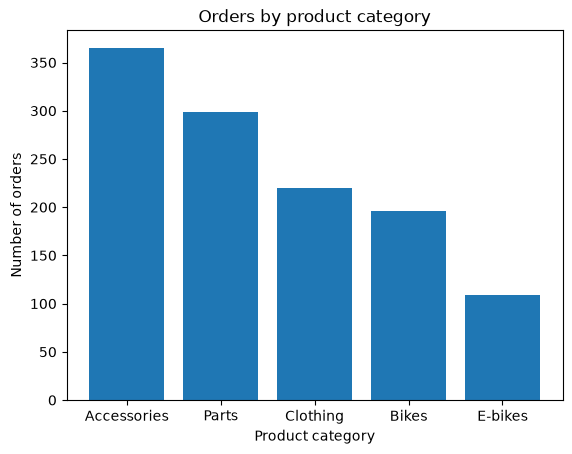

In [42]:
category_counts = sales["product_category"].value_counts()
print(category_counts)
plt.bar(category_counts.index, category_counts.values)
plt.title("Orders by product category")
plt.xlabel("Product category")
plt.ylabel("Number of orders")
plt.show()

Explain what the histogram in 2.3 and the bar chart in 2.4 tell you about a typical order at this shop.

*Your answer:* Most orders are small: 814 of 1,189 are a single item and only 19 have more than 4. The distribution is right-skewed with a few bulk orders far out on the right. Accessories are the most common category (365 orders), then Parts (299), Clothing (220), Bikes (196) and E-bikes (109), so a typical order is one cheap item, not a bike.

## 3. Bivariate analysis: two columns at a time

Bivariate analysis looks at how two variables behave together. The chart depends on the kinds of variable, as on the "Bivariate Analysis" slide: numeric and numeric is a scatter plot, numeric and categorical is a box plot, and categorical and categorical is a crosstab or grouped bar chart.

### 3.1 Are order quantities related to unit price?

Draw a scatter plot with `unit_price` on the x-axis and `quantity` on the y-axis. Then calculate the Pearson correlation between the two columns.

| You'll need | What it's for |
|---|---|
| `plt.scatter(..., ...)` | One dot per row: x values first, then y values. |
| `sales["..."].corr(sales["..."])` | Pearson's r between two numeric columns, from -1 to +1. |

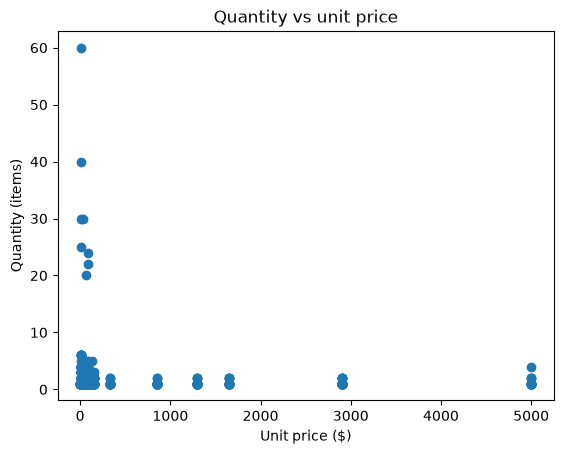

np.float64(-0.0973386215823352)

In [43]:
plt.scatter(sales["unit_price"], sales["quantity"])
plt.title("Quantity vs unit price")
plt.xlabel("Unit price ($)")
plt.ylabel("Quantity (items)")
plt.show()
sales["quantity"].corr(sales["unit_price"])

Explain what the value of r says about quantity and unit price, and what the scatter plot shows that r doesn't.

*Your answer:* r is -0.10, which is close to 0, so there's almost no straight-line relationship. The scatter plot still shows a clear pattern: every order with more than 6 items is for something under $150, and anything over $300 (bikes and e-bikes) is bought 1 or 2 at a time. It's an L shape, not a line, so r misses it.

### 3.2 Are order values different across membership types?

The shop has three membership types: `Non-member`, `Basic` and `Premium`. Draw one box plot of `order_value` per membership type, side by side, with the type names under the boxes. Then show the median order value for each type.

| You'll need | What it's for |
|---|---|
| `sales[sales["membership_type"] == ...]["order_value"]` | The order values for one membership type, using a boolean mask. |
| `plt.boxplot([...], tick_labels=[...])` | A list of columns gives one box each; `tick_labels` names them. |
| `.groupby(...)["..."].median()` | The median of one column for each group. |

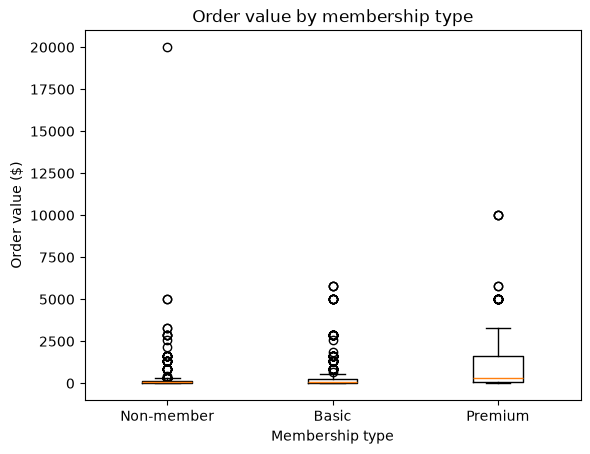

membership_type
Basic          85.0
Non-member     70.0
Premium       329.0
Name: order_value, dtype: float64

In [44]:
types = ["Non-member", "Basic", "Premium"]
values = [sales[sales["membership_type"] == t]["order_value"] for t in types]
plt.boxplot(values, tick_labels=types)
plt.title("Order value by membership type")
plt.xlabel("Membership type")
plt.ylabel("Order value ($)")
plt.show()
sales.groupby("membership_type")["order_value"].median()

Explain how order values differ between the three membership types, using the medians and the boxes.

*Your answer:* Premium members spend much more per order: their median is $329 against $85 for Basic and $70 for non-members, and their box reaches up to about $1,650 while the other two boxes stay under about $270. All three groups have dots up in the thousands, which are the bike and e-bike orders.

### 3.3 Membership type by city

Count how many orders each membership type placed in each city, as a table.

| You'll need | What it's for |
|---|---|
| `pd.crosstab(..., ...)` | A table of counts for two categorical columns: the first gives the rows, the second the columns. |

In [45]:
pd.crosstab(sales["membership_type"], sales["city"])

city,Edmonton,Leduc,Sherwood Park,Spruce Grove,St. Albert
membership_type,,,,,
Basic,270,44,45,41,76
Non-member,221,27,55,37,44
Premium,245,20,13,14,23


## 4. Over time, and more than two columns at once

### 4.1 How do monthly orders change over time?

Add a `month` column to `sales` holding each order's year and month as text (for example `2026-05`). Count the orders in each month, in date order, and draw them as a line chart.

| You'll need | What it's for |
|---|---|
| `.dt.to_period("M").astype(str)` | The `.dt` accessor works on dates; `to_period("M")` keeps only the year and month, and `astype(str)` turns it into text labels. |
| `.value_counts().sort_index()` | Counts per month, then sorts by the month labels instead of by count. |
| `plt.plot(..., ...)` | A line chart: x values first, then y values. |
| `plt.xticks(rotation=...)` | Turns the x-axis labels so they don't overlap. |

month
2025-11     55
2025-12    147
2026-01     37
2026-02     29
2026-03     68
2026-04    148
2026-05    143
2026-06    173
2026-07    110
2026-08    102
2026-09     87
2026-10     90
Name: count, dtype: int64


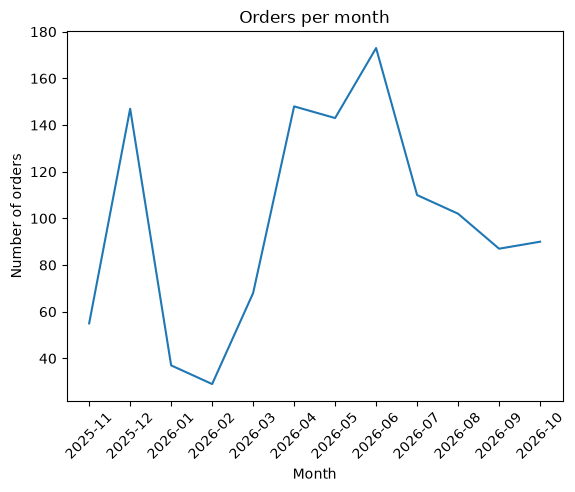

In [46]:
sales["month"] = sales["order_date"].dt.to_period("M").astype(str)
monthly = sales["month"].value_counts().sort_index()
print(monthly)
plt.plot(monthly.index, monthly.values)
plt.title("Orders per month")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.xticks(rotation=45)
plt.show()

Explain the pattern in the line chart. Which months are busy, which are quiet, and is there anything that doesn't fit a simple "busy in summer" story?

*Your answer:* Orders climb from 29 in February to a peak of 173 in June, then fall back to around 90 by September and October. That's the riding season. The odd one out is December: 147 orders, almost as many as April, sitting between a quiet November (55) and the quietest months, January (37) and February (29).

### 4.2 Is December busy in every category?

The line raises a new question, just like the "Example of EDA iteration" slide: is the December spike true across all categories? Make a crosstab of `product_category` by `month` and draw it as a heatmap, with a colour bar and the category and month names on the axes.

| You'll need | What it's for |
|---|---|
| `pd.crosstab(..., ...)` | Orders for each category (rows) in each month (columns). |
| `plt.imshow(..., aspect=...)` | Draws a table of numbers as a grid of coloured cells. Passing `aspect="auto"` lets the cells stretch to fill the chart; by default they stay square, which makes a 5 × 12 grid very small. |
| `plt.colorbar(label=...)` | Adds the key that says what each colour means. |
| `plt.xticks(range(...), ..., rotation=...)`, `plt.yticks(range(...), ...)` | Puts the month and category names on the squares' positions. |

month             2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  \
product_category                                                         
Accessories            16       66       10       12       12       38   
Bikes                   2        5        3        3       15       31   
Clothing               25       51       14        4        9       17   
E-bikes                 0        5        3        1       12       16   
Parts                  12       20        7        9       20       46   

month             2026-05  2026-06  2026-07  2026-08  2026-09  2026-10  
product_category                                                        
Accessories            38       56       34       34       25       24  
Bikes                  34       50       14       18       12        9  
Clothing               12       11       10       15       21       31  
E-bikes                16       16       17       10        9        4  
Parts                  43       40       35

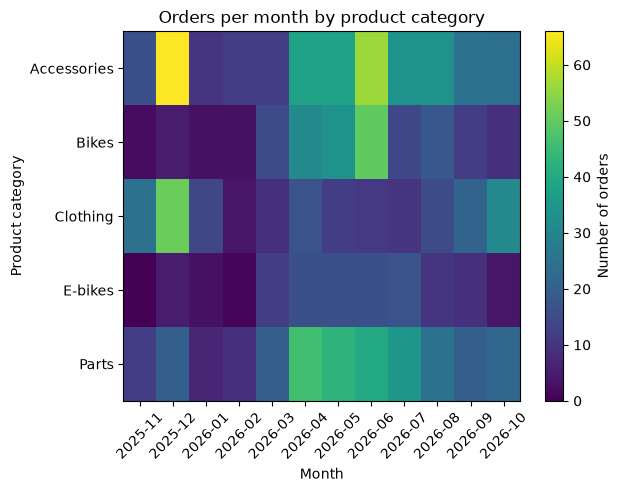

In [47]:
by_month = pd.crosstab(sales["product_category"], sales["month"])
print(by_month)
plt.imshow(by_month, aspect="auto")
plt.colorbar(label="Number of orders")
plt.xticks(range(len(by_month.columns)), by_month.columns, rotation=45)
plt.yticks(range(len(by_month.index)), by_month.index)
plt.title("Orders per month by product category")
plt.xlabel("Month")
plt.ylabel("Product category")
plt.show()

Explain whether the December spike happens in every category, and what that suggests about why December is busy.

*Your answer:* No. December is the busiest month of the year for Accessories (66) and Clothing (51), but Bikes (5) and E-bikes (5) are near their lowest. Parts goes up a bit (20). So the December spike is small items like gloves, lights and helmets, which looks like Christmas gift shopping, while bikes sell in spring and summer.

## 5. What we can say, and what we can't yet

EDA finds things worth investigating. It doesn't explain why they happen.

Explain one observation you can state confidently from the charts above, one explanation for it that the data so far can't confirm, and the next thing you'd check to test that explanation.

*Your answer:* Premium members spend more per order (median $329 against $85 and $70). It's tempting to say the membership makes people spend more, but the data can't show that. Premium might just be the membership that keen cyclists buy, and keen cyclists buy bikes. Next I'd make a crosstab of membership type by product category to see whether Premium members buy more bikes and e-bikes.

## 6. Back to the owner

Explain, in four or five sentences the owner could read in a minute, what you found. Use numbers from the charts, mention the order that needs checking, and end with one question for the owner.

*Your answer:* Your year has two busy seasons, not one. Bike and e-bike sales run from April to August and peak in May and June (173 orders in June), and then there's a second spike in December (147 orders) that's almost all gloves, lights, helmets and clothing, with hardly any bikes. January and February are the quietest months, under 40 orders each. Premium members spend about four times as much per order as everyone else (median $329 vs $70 to $85). One order on 16 May says 500 commuter bikes for $424,500, which I've left out because it looks like a typo: what was that order supposed to be?

## 7. EDA challenge: the workshop

The owner sends a second file:

> *"While you're at it, the repair workshop has been chaos since spring. Anything in there?"*

`workshop_jobs.csv` has one row per repair job from March to October 2026. Do a short EDA on it on your own, following the "EDA challenge" slide. There's no single right set of charts; pick the ones that fit the questions you want to ask.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(..., parse_dates=[...])`, `.shape`, `.head()`, `.dtypes`, `.isna().sum()` | Loading and getting to know the file, as in section 1. |
| `.describe()` | Descriptive statistics for the numeric columns. |
| `plt.hist`, `plt.boxplot`, `plt.bar`, `plt.scatter`, `plt.plot` | The chart types from sections 2 to 4. |
| `.groupby(...)[...].median()`, `.value_counts()`, `pd.crosstab(...)` | Summaries by group, when a chart needs counts or medians first. |

### 7.1 Load the file into a DataFrame called `jobs` and show the number of rows and columns.

(430, 9)
job_id                        str
drop_off_date      datetime64[us]
service_type                  str
bike_type                     str
mechanic                      str
labour_hours              float64
parts_cost                float64
turnaround_days             int64
customer_rating           float64
dtype: object
job_id               0
drop_off_date        0
service_type         0
bike_type            0
mechanic             0
labour_hours         0
parts_cost           6
turnaround_days      0
customer_rating    128
dtype: int64


,job_id,drop_off_date,service_type,bike_type,mechanic,labour_hours,parts_cost,turnaround_days,customer_rating
0,W-3001,2026-03-01,Flat repair,Mountain,Priya,0.25,24.00,3,NaN
1,W-3002,2026-03-01,Full tune-up,Road,Marc,2.50,164.62,3,NaN
2,W-3003,2026-03-01,Brake service,Mountain,Marc,1.00,42.95,1,5.0
3,W-3004,2026-03-02,Flat repair,Commuter,Marc,0.25,0.00,2,5.0
4,W-3005,2026-03-02,Full tune-up,Kids,Marc,1.75,54.39,2,4.0


### 7.2 Explain at least three different variable types in `jobs`, with an example column for each.

*Your answer:* Continuous numeric: `labour_hours`, `parts_cost`. Discrete numeric: `turnaround_days` (whole days). Categorical: `service_type`, `bike_type`, `mechanic`. Ordinal: `customer_rating` (1 to 5, the order matters but the gaps aren't measured). Date: `drop_off_date`. `job_id` is an identifier.

### 7.3 Calculate descriptive statistics for two numeric variables.

,labour_hours,turnaround_days
count,430.000000,430.000000
mean,1.322674,4.855814
std,0.879270,2.922886
min,0.250000,1.000000
25%,0.500000,3.000000
50%,1.250000,5.000000
75%,1.750000,6.000000
max,4.500000,41.000000


### 7.4 Create two visualizations using different chart types.

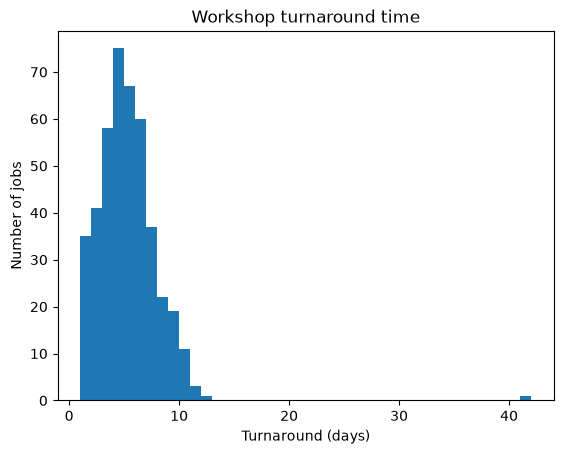

month
2026-03    3.0
2026-04    4.0
2026-05    6.0
2026-06    6.0
2026-07    5.0
2026-08    4.0
2026-09    3.0
2026-10    2.0
Name: turnaround_days, dtype: float64


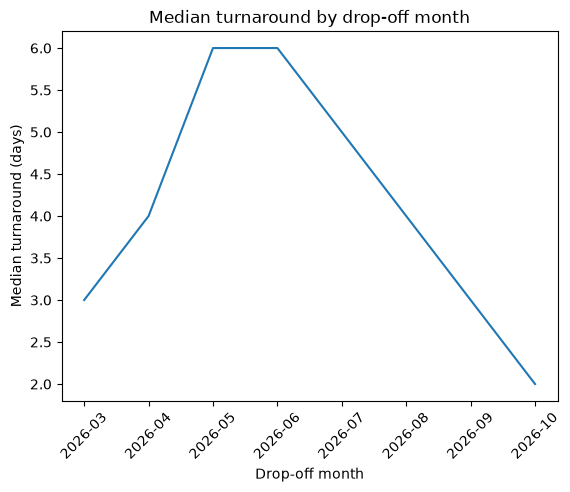

### 7.5 Explain at least two observations from your statistics and charts.

*Your answer:*

### 7.6 Explain one new question that comes from something you discovered.

*Your answer:*